# Early Detection of Chronic Kidney Disease with Missing Clinical Data

**Classification | SDG 3: Good Health and Well-Being**

Educational, reproducible comparison of imputation strategies and classifiers on the UCI CKD dataset. This is not a diagnostic tool.

**Question:** How do median/mode and KNN imputation affect CKD classification? We compare logistic regression and random forest with repeated stratified cross-validation. All preprocessing is fitted within each fold to prevent leakage.

## Dataset and attribution
The UCI CKD dataset contains 400 patient records, 24 clinical predictors, and a CKD/not-CKD target, with missing values. Cite: Rubini, L., Soundarapandian, P., & Eswaran, P. (2015). *Chronic Kidney Disease* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5G020. License: CC BY 4.0.

Your ZIP contains a nested RAR. If the UCI download below fails, extract both archive layers on your computer and upload the extracted data file (CSV, DATA, or ARFF) in the manual upload cell.

In [8]:
%pip -q install ucimlrepo

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

# UCI dataset id 336
dataset = fetch_ucirepo(id=336)
X = dataset.data.features.copy()
y = dataset.data.targets.iloc[:, 0].copy()
df = X.copy()
df['class'] = y
print('Shape:', df.shape)
display(df.head())
display(df['class'].value_counts(dropna=False))

Shape: (400, 25)


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


,count
class,
ckd,248
notckd,150
ckd\t,2


In [10]:
# OPTIONAL CSV upload example
# from google.colab import files
# uploaded = files.upload()
# filename = next(iter(uploaded))
# df = pd.read_csv(filename, na_values=['?', ''])
# df.columns = [str(c).strip().lower() for c in df.columns]


## 1. Inspect and clean
Convert missing markers and trim text values. Do not use the target to fill clinical features.

Shape: (400, 25) | duplicate rows: 0


,count
class,
ckd,250
notckd,150


,missing_count,missing_percent
rbc,152,38.0
rbcc,131,32.8
wbcc,106,26.5
pot,88,22.0
sod,87,21.8
pcv,71,17.8
pc,65,16.2
hemo,52,13.0
su,49,12.2
sg,47,11.8


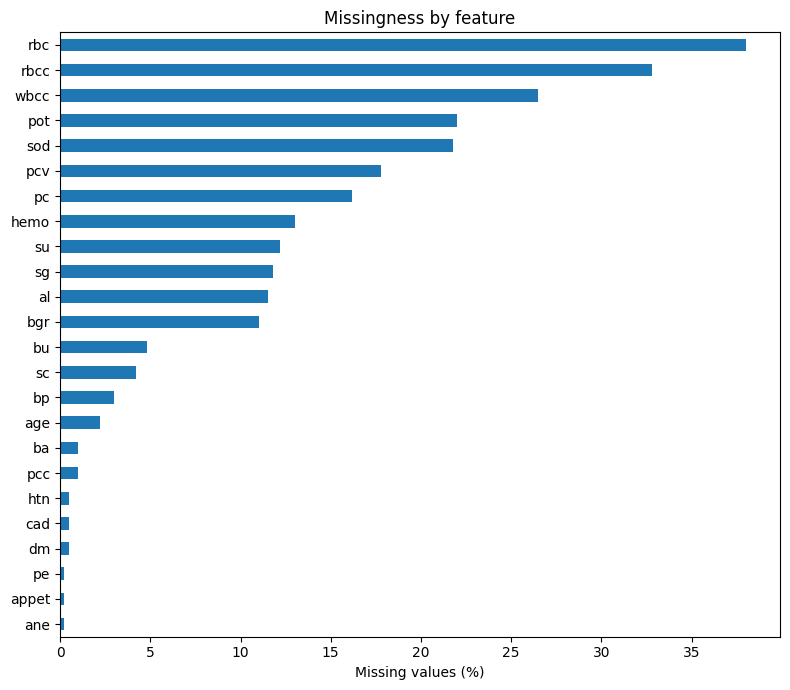

In [11]:
df.columns = [str(c).strip().lower() for c in df.columns]
df = df.replace(r'^\s*\?\s*$', np.nan, regex=True).replace(r'^\s*$', np.nan, regex=True)
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].map(lambda v: v.strip().lower() if isinstance(v, str) else v)
if 'class' not in df.columns: raise ValueError("Target column must be named 'class'.")
df['class'] = df['class'].replace({'not ckd':'notckd', 'ckd\t':'ckd', 'notckd\t':'notckd'})
df = df.dropna(subset=['class']).copy()
print('Shape:', df.shape, '| duplicate rows:', df.duplicated().sum())
display(df['class'].value_counts().rename('count').to_frame())
missing = df.drop(columns='class').isna().sum().to_frame('missing_count')
missing['missing_percent'] = (100*missing['missing_count']/len(df)).round(1)
display(missing.sort_values('missing_percent', ascending=False))
missing.sort_values('missing_percent').plot.barh(y='missing_percent', figsize=(8,7), legend=False)
plt.xlabel('Missing values (%)'); plt.title('Missingness by feature'); plt.tight_layout(); plt.show()

## 2. Prepare predictors and target
The target is mapped to 1=CKD and 0=not CKD. Numeric-like columns imported as text are converted when possible.

In [12]:
X = df.drop(columns='class').copy()
y = df['class'].astype(str).str.strip().str.lower().map({'ckd':1, 'notckd':0, 'not ckd':0})
if y.isna().any(): raise ValueError('Unexpected class values; inspect df["class"].value_counts() and update mapping.')
y = y.astype(int)
for col in X.select_dtypes(include='object').columns:
    conv = pd.to_numeric(X[col], errors='coerce')
    if conv.notna().sum() > 0 and conv.notna().sum() >= .8*X[col].notna().sum(): X[col] = conv
numeric_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]
print('Numeric:', numeric_features)
print('Categorical:', categorical_features)
print('CKD prevalence:', round(y.mean(),3))

Numeric: ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc']
Categorical: ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']
CKD prevalence: 0.625


## 3. Compare imputation and classification
Median/mode: median imputation for numeric fields, most frequent for categories. KNN/mode: KNN imputation for numeric fields and most frequent for categories. Both pipelines one-hot encode categorical values. Repeated stratified 5-fold CV (5 repeats) reports accuracy, CKD recall/sensitivity, F1, and ROC-AUC. Recall helps show how often CKD cases are detected.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

def preprocessor(method):
    num_imp = SimpleImputer(strategy='median') if method == 'median_mode' else KNNImputer(n_neighbors=5)
    num = Pipeline([('impute',num_imp),('scale',StandardScaler())])
    cat = Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore'))])
    return ColumnTransformer([('num',num,numeric_features),('cat',cat,categorical_features)])

models = {'Logistic Regression': LogisticRegression(max_iter=3000, class_weight='balanced', random_state=42), 'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1)}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
scoring = {'accuracy':'accuracy','recall':'recall','f1':'f1','roc_auc':'roc_auc'}
rows = []
for imp in ['median_mode','knn_mode']:
    for model_name, model in models.items():
        pipe = Pipeline([('prep',preprocessor(imp)),('model',model)])
        scores = cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=-1, error_score='raise')
        row = {'Imputation':imp,'Classifier':model_name}
        for metric in scoring:
            vals = scores['test_'+metric]
            row[metric+'_mean'] = vals.mean(); row[metric+'_sd'] = vals.std(ddof=1)
        rows.append(row)
results_df = pd.DataFrame(rows).sort_values('roc_auc_mean',ascending=False).reset_index(drop=True)
display(results_df.round(3))

,Imputation,Classifier,accuracy_mean,accuracy_sd,recall_mean,recall_sd,f1_mean,f1_sd,roc_auc_mean,roc_auc_sd
0,median_mode,Logistic Regression,0.989,0.012,0.982,0.019,0.991,0.010,1.000,0.000
1,median_mode,Random Forest,0.992,0.008,0.996,0.008,0.994,0.006,1.000,0.000
2,knn_mode,Logistic Regression,0.986,0.013,0.983,0.017,0.988,0.010,0.999,0.001
3,knn_mode,Random Forest,0.984,0.014,0.994,0.010,0.987,0.011,0.999,0.001


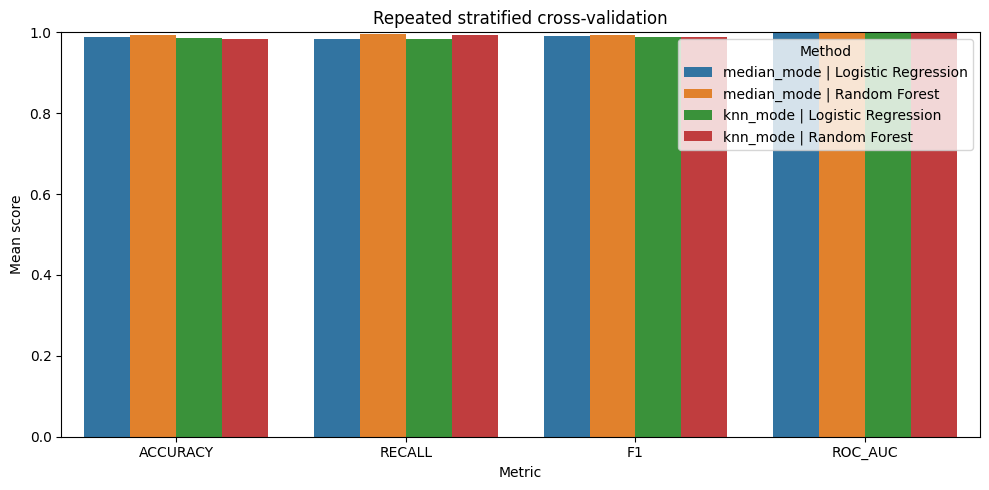

Saved ckd_cv_results.csv


In [14]:
plot_df = results_df.melt(id_vars=['Imputation','Classifier'], value_vars=['accuracy_mean','recall_mean','f1_mean','roc_auc_mean'], var_name='Metric', value_name='Mean score')
plot_df['Metric'] = plot_df['Metric'].str.replace('_mean','',regex=False).str.upper()
plot_df['Method'] = plot_df['Imputation'] + ' | ' + plot_df['Classifier']
plt.figure(figsize=(10,5)); sns.barplot(data=plot_df,x='Metric',y='Mean score',hue='Method'); plt.ylim(0,1); plt.title('Repeated stratified cross-validation'); plt.tight_layout(); plt.show()
results_df.to_csv('ckd_cv_results.csv',index=False)
print('Saved ckd_cv_results.csv')

## 4. Report interpretation and limitations
Report the mean and standard deviation across folds. Compare recall and ROC-AUC as well as accuracy; explain the implications of missed CKD cases and the trade-offs among methods. Do not claim clinical readiness.

**Limitations:** only 400 records; one India-based data source and short collection window; potential selection/measurement bias; no external validation; missingness mechanisms may be unknown. This is a retrospective educational classification exercise, not prospective early-detection validation.

### Suggested short communication structure
1. Introduction: CKD context, SDG 3, aim and question.
2. Materials and Methods: source, missingness, cleaning, pipelines, classifiers, cross-validation, metrics.
3. Results: class balance, missingness table/plot, metric table/plot.
4. Discussion: findings, recall trade-offs, limitations.
5. Conclusion: concise answer and need for external validation.
6. References: UCI dataset and supporting literature.

A short communication is a suitable format for this focused assignment. Check the exact journal called *Current Science* and its current author instructions before considering submission; similarly named journals have different policies.